# ThreadNet — pipeline walkthrough

This notebook illustrates the full ThreadNet pipeline for the
[Solar Filament Segmentation Challenge 2026](https://www.kaggle.com/competitions/filament-segmentation-2026):
**detect** (YOLO11) -> **crop** (padded, aspect-preserving letterbox) ->
**refine** (edge-attention U-Net, optional flip-4 test-time augmentation) ->
**stitch** (mask-level non-maximum suppression) -> **evaluate** (Panoptic
Quality, the competition's ranking metric).

It runs each stage on one real validation image so every intermediate
representation is visible, then evaluates PQ over a small batch of
validation images with the best-known configuration
(axis-aligned + flip-4 TTA, `conf_thres=0.35`, `mask_nms_thresh=0.15`,
PQ=0.4405 on the full held-out split).

For the full methodology, the five extensions we tried, and why only
flip-TTA survived validation, see the accompanying technical report at
[`kaggle_comp_report_fi_segm_Marchezi_2026/main.tex`](../kaggle_comp_report_fi_segm_Marchezi_2026/main.tex).
For every CLI command to reproduce training end to end, see the
[README](../README.md).

This notebook assumes the package is installed (`pip install -e .` from the
repo root) and that `filament prepare` + `filament train-yolo` +
`filament train-unet` have already been run once, so trained weights exist
under `work/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from ultralytics import YOLO

from solar_filaments.config import Paths, YoloConfig, UNetConfig, CropConfig, InferenceConfig
from solar_filaments.data.coco import Dataset, load_split, load_image, polygon_to_mask
from solar_filaments.data.crop_dataset import padded_rect_crop, letterbox_resize
from solar_filaments.inference import predict_instances, _segment, _segment_tta
from solar_filaments.eval.self_eval import build_val_gt_pred_dataframes, get_overlap_df, get_pq_score
from solar_filaments.models.unet import EdgeAttUNet

paths = Paths()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("data root:", paths.data_root)
print("work dir:", paths.work_dir)
print("device:", device)


/home/marchezi/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


data root: /data/marchezi/filament_segmentation_2026/MAGFiLO_1.0_Kaggle_2026
work dir: /home/marchezi/python_projects/solar_filaments_detection/work
device: cuda


## 1. Dataset and the leak-safe train/validation split

MAGFiLO images can carry 1-3 independent annotator labelings that share one physical `file_name`. Every split in this project groups by `file_name`, not by the per-annotator image record, so the same photograph never appears in both train and validation under two different annotator IDs.

In [2]:
dataset = Dataset(paths.train_ann_path)
print(dataset.summary())

_, val_ids = load_split(paths.split_path_for(None))
val_ids = sorted(val_ids)
print(f"validation image records: {len(val_ids)}")


1154 image records over 707 unique images (296 with >1 annotator), 8199 filament instances (7.10 filaments/image-record on average); categories={1: 'Left', 2: 'Right', 3: 'Unidentifiable', 4: 'Ambiguous'}
validation image records: 104


## 2. Detect: YOLO11 proposes a box per filament

The detector runs on the full-disk image downsampled to 1024x1024 and outputs an axis-aligned box (plus a confidence score) per candidate filament.

9 detections on 20120330063134Lh.jpeg


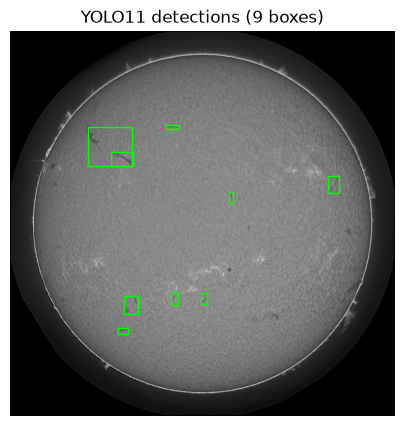

In [3]:
yolo_model = YOLO(str(paths.runs_dir / YoloConfig().name / "weights" / "best.pt"))

img_id = val_ids[0]
info = dataset.images_by_id[img_id]
img_path = paths.train_img_dir / info["file_name"]
img = load_image(img_path)
H, W = img.shape

det = yolo_model.predict(img, conf=0.35, iou=0.5, imgsz=1024, verbose=False)[0]
boxes = det.boxes.xyxy.cpu().numpy()
scores = det.boxes.conf.cpu().numpy()
print(f"{len(boxes)} detections on {info['file_name']}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(img, cmap="gray", vmin=0, vmax=255)
for (x1, y1, x2, y2), s in zip(boxes, scores):
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=1))
ax.set_title(f"YOLO11 detections ({len(boxes)} boxes)")
ax.axis("off")
plt.show()


## 3. Crop: pad and letterbox to preserve the filament's aspect ratio

Filaments are long and thin — a naive square crop around an elongated box wastes most of its resolution on empty margin once resized. Instead the box is padded independently in width/height, then letterbox-resized (scaled to fit, zero-padded) into a square canvas.

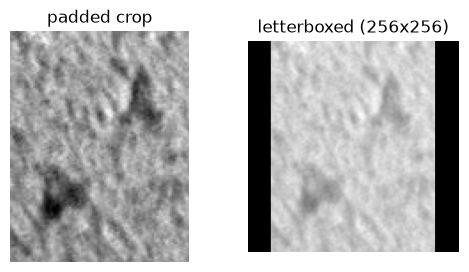

In [4]:
crop_cfg = CropConfig()
order = np.argsort(-scores)
x1b, y1b, x2b, y2b = boxes[order[0]]
x, y, w, h = x1b, y1b, x2b - x1b, y2b - y1b
cx1, cy1, cx2, cy2 = padded_rect_crop(x, y, w, h, W, H, crop_cfg.pad_factor, crop_cfg.min_crop_side)
crop = img[cy1:cy2, cx1:cx2]
crop_letterboxed, scale, left, top = letterbox_resize(crop, crop_cfg.crop_size)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(crop, cmap="gray"); axes[0].set_title("padded crop"); axes[0].axis("off")
axes[1].imshow(crop_letterboxed, cmap="gray"); axes[1].set_title(f"letterboxed ({crop_cfg.crop_size}x{crop_cfg.crop_size})"); axes[1].axis("off")
plt.show()


## 4. Refine: U-Net segments the crop, with optional flip-4 TTA

The U-Net predicts a probability map for the crop. With `--tta`, the prediction is averaged over 4 flips (identity/horizontal/vertical/both) and the average is trusted only if it doesn't change the single-view mask's topology (area ratio, connected-component count, Dice overlap guards) — otherwise inference falls back to the single-view mask.

*(`_segment`/`_segment_tta` are internal helpers, imported here only to expose this intermediate step for illustration — normal usage goes through the public `predict_instances`, shown in the next section.)*

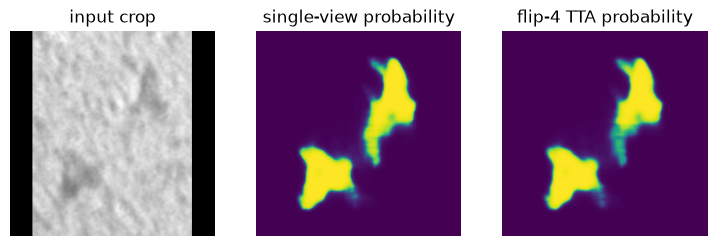

In [5]:
unet_model = EdgeAttUNet(use_edge_attention=UNetConfig().use_edge_attention).to(device)
unet_model.load_state_dict(torch.load(paths.ckpt_dir / "unet_best.pt", map_location=device))
unet_model.eval()

with torch.no_grad():
    mask_single, prob_single, *_ = _segment(unet_model, device, crop, crop_cfg.crop_size, InferenceConfig().mask_thresh)
    mask_tta, prob_tta, *_ = _segment_tta(unet_model, device, crop, crop_cfg.crop_size, InferenceConfig().mask_thresh)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(crop_letterboxed, cmap="gray"); axes[0].set_title("input crop"); axes[0].axis("off")
axes[1].imshow(prob_single, cmap="viridis", vmin=0, vmax=1); axes[1].set_title("single-view probability"); axes[1].axis("off")
axes[2].imshow(prob_tta, cmap="viridis", vmin=0, vmax=1); axes[2].set_title("flip-4 TTA probability"); axes[2].axis("off")
plt.show()


## 5. Stitch: full end-to-end instance map

`predict_instances` runs every step above for every detected box on the full image, then merges the resulting crop-level masks into one non-overlapping instance label map with a greedy, confidence-ordered mask-level NMS (a candidate is rejected if it's already mostly covered by a higher-confidence instance).

8 final instances


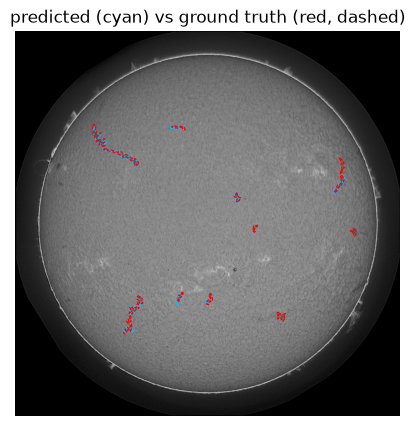

In [6]:
label_map, inst_scores = predict_instances(
    img_path, yolo_model, unet_model, device,
    conf_thres=0.35, mask_nms_thresh=0.15, use_tta=True,
)
print(f"{len(inst_scores)} final instances")

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(img, cmap="gray", vmin=0, vmax=255)
for inst_id in range(1, int(label_map.max()) + 1):
    mask = (label_map == inst_id).astype(np.uint8)
    if mask.any():
        ax.contour(mask, levels=[0.5], colors="deepskyblue", linewidths=1.0)
for ann in dataset.anns_by_image[img_id]:
    gt_mask = polygon_to_mask(ann["segmentation"], H, W)
    ax.contour(gt_mask, levels=[0.5], colors="red", linewidths=0.8, linestyles="dashed")
ax.set_title("predicted (cyan) vs ground truth (red, dashed)")
ax.axis("off")
plt.show()


## 6. Evaluate: Panoptic Quality

PQ matches predicted and ground-truth instances globally by IoU > 0.5 and pools true/false positives and negatives across every image before dividing — a stricter aggregation than a per-image mean. This mirrors the organizers' own self-evaluation logic exactly (`src/solar_filaments/eval/self_eval.py`). We evaluate a small batch here for a fast, illustrative number; the full held-out split (674 ground-truth filaments) gives PQ=0.4405 for this configuration, see the report for the complete comparison across every extension we tried.

In [7]:
crop_cfg = CropConfig()
inference_cfg = InferenceConfig(conf_thres=0.35, mask_nms_thresh=0.15)

sample_ids = val_ids[:8]
gt_df, pred_df = build_val_gt_pred_dataframes(
    dataset, paths.train_img_dir, sample_ids, yolo_model, unet_model, device,
    crop_cfg, inference_cfg, use_tta=True,
)
overlap_df = get_overlap_df(gt_df, pred_df)
pq = get_pq_score(overlap_df)
print(f"GT filaments: {len(gt_df)}   predicted filaments: {len(pred_df)}")
print(f"PQ on this {len(sample_ids)}-image sample: {pq:.4f}")


GT filaments: 62   predicted filaments: 20
PQ on this 8-image sample: 0.3734


## 7. What else we tried

Five independent extensions to this baseline were implemented and validated
against the same held-out split before being adopted or discarded:

| Extension | Result |
|---|---|
| 5-fold CV + copy-paste augmentation | ties baseline (0.4368) |
| Oriented bounding boxes (OBB) | better instance quality, lower recall (0.4207-0.4321 depending on ensembling) |
| Ensemble (axis-aligned + OBB + classical) | below best individual model (0.4321) |
| Photometric normalization (limb-darkening + CLAHE) | below baseline (0.4248) |
| InstanceNorm U-Net | ties baseline (0.4345) |
| **Flip-4 topology-safe TTA (adopted)** | **beats baseline: 0.4381 -> 0.4405** |

See the [technical report](../kaggle_comp_report_fi_segm_Marchezi_2026/main.tex)
for the full discussion, and the [README](../README.md) for the exact CLI
command behind every row.